## Лабораторная работа №1 | Вариант 6

Выполнил: 

### 1. Numpy

In [1]:
import numpy as np

rng = np.random.default_rng(42)  # Воспроизводимые случайные примеры.

1. Создайте единичную матрицу размером 3х3

In [2]:
identity_matrix = np.eye(3, dtype=int)
identity_matrix

array([[1, 0, 0],
       [0, 1, 0],
       [0, 0, 1]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [ ]:
subdiagonal_matrix = np.diag(np.arange(1, 5), k=-1)
subdiagonal_matrix

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [4]:
# До импорта используется встроенная sum: -1 — начальная сумма.
print(sum(range(5), -1))  # 9
# После from numpy import * имя sum обозначает np.sum, а -1 — ось.
print(np.sum(range(5), -1))  # 10

9
10


4. Как найти самое часто встречаемое значение между двумя массивами? 

In [ ]:
first_array = np.array([1, 2, 2, 3, 3])
second_array = np.array([2, 3, 3, 4, 5])

values, counts = np.unique(np.concatenate((first_array, second_array)),
                           return_counts=True)
modes = values[counts == counts.max()]
print("Самые частые значения:", modes, "; число вхождений:", counts.max())


Самые частые значения: [3] ; число вхождений: 4
Самые частые общие значения: [3]


5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [6]:
import warnings

# np.errstate подавляет предупреждения вычислений NumPy;
# warnings.simplefilter — остальные Python warnings внутри блока.
# После выхода из блока прежние настройки автоматически восстанавливаются.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    with np.errstate(all="ignore"):
        print(np.array([1.0, 0.0]) / 0)  # [inf nan], без предупреждений.

[inf nan]


6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [ ]:
def integer_generator():
    for number in range(10):
        yield number


generated_array = np.fromiter(integer_generator(), dtype=np.int64, count=10)
generated_array

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [8]:
random_array = rng.random(10)
print("Исходный массив:", random_array)
random_array.sort()
print("После сортировки:", random_array)

Исходный массив: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735 0.97562235
 0.7611397  0.78606431 0.12811363 0.45038594]
После сортировки: [0.09417735 0.12811363 0.43887844 0.45038594 0.69736803 0.7611397
 0.77395605 0.78606431 0.85859792 0.97562235]


8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [9]:
cartesian_coordinates = rng.uniform(-10, 10, size=(10, 2))
x, y = cartesian_coordinates.T
radii = np.hypot(x, y)
angles = np.arctan2(y, x)  # Угол в радианах, с учётом четверти.
polar_coordinates = np.column_stack((radii, angles))
print("Декартовы координаты (x, y):\n", cartesian_coordinates)
print("Полярные координаты (r, угол в радианах):\n", polar_coordinates)

Декартовы координаты (x, y):
 [[-2.58403952  8.53529978]
 [ 2.8773024   6.45523227]
 [-1.13171602 -5.45522556]
 [ 1.09169574 -8.72365488]
 [ 6.55262344  2.63328798]
 [ 5.1617548  -2.90948064]
 [ 9.41396049  7.86242243]
 [ 5.56766994 -6.10722584]
 [-0.66557993 -9.12392468]
 [-6.91421016  3.66097906]]
Полярные координаты (r, угол в радианах):
 [[ 8.91788105  1.86477173]
 [ 7.06745306  1.15149749]
 [ 5.57137928 -1.77535016]
 [ 8.79169802 -1.44630151]
 [ 7.06194588  0.38211546]
 [ 5.9252671  -0.51327108]
 [12.26541228  0.69583156]
 [ 8.26420934 -0.83158035]
 [ 9.14816912 -1.6436162 ]
 [ 7.82362255  2.65463526]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [10]:
pixel_dtype = np.dtype([
    ("x", np.int32), ("y", np.int32),
    ("r", np.uint8), ("g", np.uint8), ("b", np.uint8),
])
pixels = np.array([(0, 0, 255, 0, 0),
                   (1, 0, 0, 255, 0),
                   (0, 1, 0, 0, 255)], dtype=pixel_dtype)
print(pixels)
print("Красный канал:", pixels["r"])

[(0, 0, 255,   0,   0) (1, 0,   0, 255,   0) (0, 1,   0,   0, 255)]
Красный канал: [255   0   0]


10. Как конвертировать тип массив от float32 в int32 in place?

In [11]:
float_array = np.array([1.9, -2.3, 0.0, 4.8], dtype=np.float32)
original_address = float_array.__array_interface__["data"][0]
print("До преобразования:", float_array, float_array.dtype)

# Типы занимают по 4 байта. Записываем преобразованные значения
# в тот же буфер через int32-представление, затем меняем dtype массива.
# Пример содержит конечные числа в диапазоне int32; дробная часть отбрасывается.
np.copyto(float_array.view(np.int32), float_array, casting="unsafe")
float_array.dtype = np.int32

print("После преобразования:", float_array, float_array.dtype)
print("Адрес буфера сохранился:",
      float_array.__array_interface__["data"][0] == original_address)
# Одна лишь смена dtype переинтерпретирует биты, а astype обычно создаёт копию.

До преобразования: [ 1.9 -2.3  0.   4.8] float32
После преобразования: [ 1 -2  0  4] int32
Адрес буфера сохранился: True


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [12]:
from pathlib import Path

import pandas as pd
from IPython.display import display

In [13]:
# Поддерживаем запуск как из папки ml, так и из корня проекта.
data_path = Path("student_perfomance.csv")
if not data_path.exists():
    data_path = Path("ml") / "student_perfomance.csv"
df = pd.read_csv(data_path)

print(f"Строк: {df.shape[0]}, столбцов: {df.shape[1]}")
display(df.head())
print("Пропущенные значения по столбцам:")
display(df.isna().sum().loc[lambda counts: counts > 0])
# Пропуски сохраняем; при сравнении образования родителей исключим
# только строки, в которых неизвестен именно этот признак.

Строк: 6607, столбцов: 20


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Пропущенные значения по столбцам:


Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [14]:
mean_sleep = df["Sleep_Hours"].mean()
print(f"Среднее время сна: {mean_sleep:.3f} часа в сутки.")

Среднее время сна: 7.029 часа в сутки.


2. Сколько процентов студентов посещают внеклассовые активности?

In [15]:
extracurricular_share = df["Extracurricular_Activities"].eq("Yes").mean() * 100
print(f"Внеклассные мероприятия посещают {extracurricular_share:.2f}% студентов.")

Внеклассные мероприятия посещают 59.60% студентов.


3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [16]:
gender_scores = df.groupby("Gender")["Exam_Score"].agg(["count", "mean"])
display(gender_scores)
gender_difference = gender_scores.loc["Female", "mean"] - gender_scores.loc["Male", "mean"]
print(f"Средний балл девушек выше на {gender_difference:.3f} балла.")
print("Формально утверждение верно для этой выборки, но разница очень мала.")

,count,mean
Gender,,
Female,2793,67.244898
Male,3814,67.228894


Средний балл девушек выше на 0.016 балла.
Формально утверждение верно для этой выборки, но разница очень мала.


4. Выведите 25 и 75 перцентили времени сна студентов

In [17]:
sleep_q25, sleep_q75 = df["Sleep_Hours"].quantile([0.25, 0.75])
print(f"25-й перцентиль: {sleep_q25:g} часов.")
print(f"75-й перцентиль: {sleep_q75:g} часов.")

25-й перцентиль: 6 часов.
75-й перцентиль: 8 часов.


5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [18]:
short_sleep_scores = df.loc[df["Sleep_Hours"] <= sleep_q25, "Exam_Score"]
long_sleep_scores = df.loc[df["Sleep_Hours"] >= sleep_q75, "Exam_Score"]
sleep_comparison = pd.DataFrame({
    "Количество студентов": [short_sleep_scores.size, long_sleep_scores.size],
    "Средний балл": [short_sleep_scores.mean(), long_sleep_scores.mean()],
}, index=[f"Сон ≤ {sleep_q25:g} ч", f"Сон ≥ {sleep_q75:g} ч"])
display(sleep_comparison)
print("Нет, утверждение не подтверждается:",
      f"у больше спящих средний балл ниже на {short_sleep_scores.mean() - long_sleep_scores.mean():.3f}.")

,Количество студентов,Средний балл
Сон ≤ 6 ч,2380,67.281092
Сон ≥ 8 ч,2486,67.187047


Нет, утверждение не подтверждается: у больше спящих средний балл ниже на 0.094.


6. Влияет ли физическая активность на результаты экзамена?

In [19]:
activity_scores = df.groupby("Physical_Activity")["Exam_Score"].agg(["count", "mean"])
activity_correlation = df["Physical_Activity"].corr(df["Exam_Score"])
display(activity_scores)
print(f"Корреляция Пирсона: {activity_correlation:.3f}.")
print("Линейная связь практически отсутствует. Причинное влияние по этим данным установить нельзя.")

,count,mean
Physical_Activity,,
0,46,67.521739
1,421,66.969121
2,1627,67.185003
3,2545,67.196071
4,1575,67.313016
5,361,67.603878
6,32,68.093750


Корреляция Пирсона: 0.028.
Линейная связь практически отсутствует. Причинное влияние по этим данным установить нельзя.


7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [20]:
education_data = df.dropna(subset=["Parental_Education_Level"]).copy()
education_data["Высшее образование родителей"] = education_data[
    "Parental_Education_Level"
].isin(["College", "Postgraduate"])
education_scores = education_data.groupby("Высшее образование родителей")[
    "Exam_Score"
].agg(["count", "mean"])
display(education_scores)
education_difference = education_scores.loc[True, "mean"] - education_scores.loc[False, "mean"]
print(f"Да, в этой выборке средний балл выше на {education_difference:.3f}.")
print(f"Исключено строк с неизвестным образованием родителей: {len(df) - len(education_data)}.")

,count,mean
Высшее образование родителей,,
False,3223,66.893577
True,3294,67.575288


Да, в этой выборке средний балл выше на 0.682.
Исключено строк с неизвестным образованием родителей: 90.


8. Как влияет участие родителей на результаты экзаменов

In [21]:
involvement_scores = df.groupby("Parental_Involvement")["Exam_Score"].agg(
    ["count", "mean"]
).reindex(["Low", "Medium", "High"])
display(involvement_scores)
print("При более высоком участии родителей средний балл выше:",
      "от {:.2f} до {:.2f}.".format(involvement_scores.loc["Low", "mean"],
                                   involvement_scores.loc["High", "mean"]))
print("Это наблюдаемая связь; она сама по себе не доказывает причинное влияние.")

,count,mean
Parental_Involvement,,
Low,1337,66.358265
Medium,3362,67.098156
High,1908,68.092767


При более высоком участии родителей средний балл выше: от 66.36 до 68.09.
Это наблюдаемая связь; она сама по себе не доказывает причинное влияние.


9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [22]:
# Доход задан категориями, поэтому «выше среднего» понимаем как High.
# Денежное среднее по этому набору вычислить нельзя.
income_scores = df.groupby("Family_Income")["Exam_Score"].agg(
    ["count", "mean"]
).reindex(["Low", "Medium", "High"])
display(income_scores)
high_income_mean = df.loc[df["Family_Income"].eq("High"), "Exam_Score"].mean()
other_income_mean = df.loc[df["Family_Income"].isin(["Low", "Medium"]), "Exam_Score"].mean()
print(f"High: {high_income_mean:.3f}; Low и Medium вместе: {other_income_mean:.3f}.")
print(f"Да, средний балл в группе High выше на {high_income_mean - other_income_mean:.3f}.")

,count,mean
Family_Income,,
Low,2672,66.848428
Medium,2666,67.334959
High,1269,67.842396


High: 67.842; Low и Medium вместе: 67.091.
Да, средний балл в группе High выше на 0.751.


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [23]:
low_income_no_internet = df.loc[
    df["Family_Income"].eq("Low") & df["Internet_Access"].eq("No")
]
above_70_count = low_income_no_internet["Exam_Score"].gt(70).sum()
above_70_share = above_70_count / len(low_income_no_internet)
print(f"Более 70 баллов: {above_70_count} из {len(low_income_no_internet)} студентов подгруппы.")
print(f"Доля: {above_70_share:.5f}, или {above_70_share:.2%}.")

Более 70 баллов: 17 из 211 студентов подгруппы.
Доля: 0.08057, или 8.06%.


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

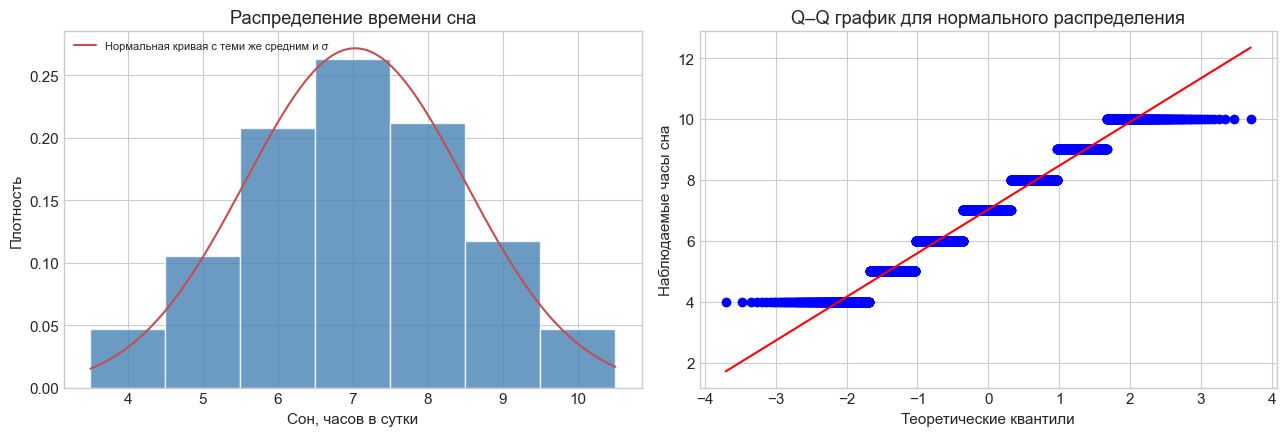

Среднее: 7.03 ч; стандартное отклонение: 1.47 ч; асимметрия: -0.024.
Да, по форме распределение примерно колоколообразное и симметричное.
Однако значения целочисленные и ограничены 4–10 часами: точной нормальности нет,
а ступени на Q–Q графике связаны с дискретностью измерений.


In [24]:
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

sleep = df["Sleep_Hours"].dropna()
sleep_mean, sleep_std = sleep.mean(), sleep.std()
grid = np.linspace(sleep.min() - 0.5, sleep.max() + 0.5, 300)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sleep, bins=np.arange(sleep.min() - 0.5, sleep.max() + 1.5),
             density=True, color="#4682b4", edgecolor="white", alpha=0.8)
axes[0].plot(grid, stats.norm.pdf(grid, sleep_mean, sleep_std),
             color="#c44e52", label="Нормальная кривая с теми же средним и σ")
axes[0].set(title="Распределение времени сна", xlabel="Сон, часов в сутки",
            ylabel="Плотность", xticks=np.arange(4, 11))
axes[0].legend(fontsize=8)
stats.probplot(sleep, dist="norm", plot=axes[1])
axes[1].set(title="Q–Q график для нормального распределения",
            xlabel="Теоретические квантили", ylabel="Наблюдаемые часы сна")
fig.tight_layout()
plt.show()

print(f"Среднее: {sleep_mean:.2f} ч; стандартное отклонение: {sleep_std:.2f} ч; асимметрия: {sleep.skew():.3f}.")
print("Да, по форме распределение примерно колоколообразное и симметричное.")
print("Однако значения целочисленные и ограничены 4–10 часами: точной нормальности нет,")
print("а ступени на Q–Q графике связаны с дискретностью измерений.")

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

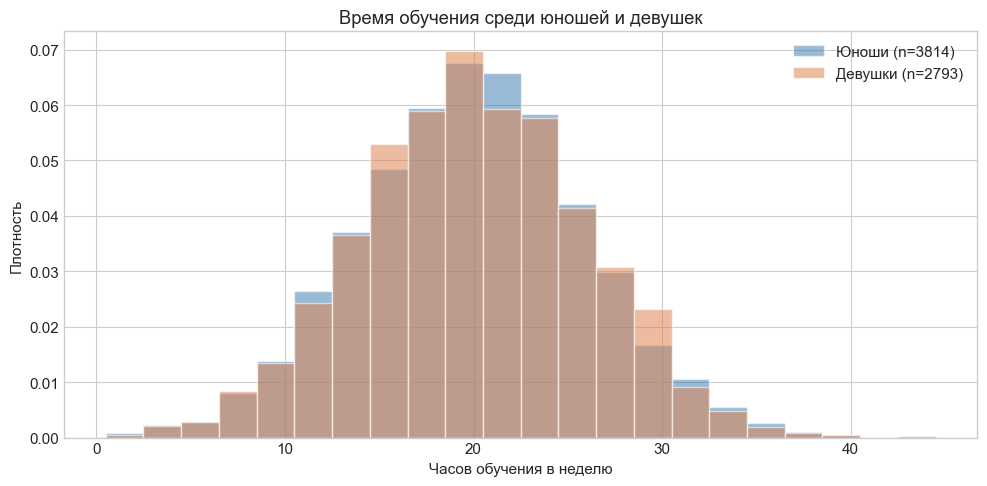

Общие интервалы и нормировка на плотность позволяют сравнить группы разного размера.


,count,mean,median
Gender,,,
Female,2793,20.005013,20.0
Male,3814,19.953592,20.0


In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
study_bins = np.arange(0.5, df["Hours_Studied"].max() + 2.5, 2)
for gender, label, color in [("Male", "Юноши", "#4682b4"),
                             ("Female", "Девушки", "#dd8452")]:
    hours = df.loc[df["Gender"].eq(gender), "Hours_Studied"]
    ax.hist(hours, bins=study_bins, alpha=0.55, density=True,
            color=color, edgecolor="white", label=f"{label} (n={len(hours)})")
ax.set(title="Время обучения среди юношей и девушек",
       xlabel="Часов обучения в неделю", ylabel="Плотность")
ax.legend()
fig.tight_layout()
plt.show()

print("Общие интервалы и нормировка на плотность позволяют сравнить группы разного размера.")
display(df.groupby("Gender")["Hours_Studied"].agg(["count", "mean", "median"]))

3. Как зависит результат конечного экзамена от результата первого экзамена

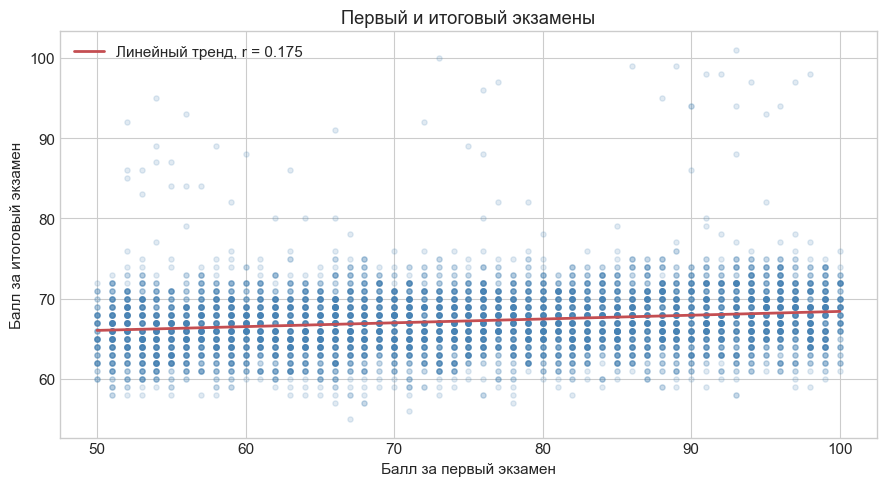

Корреляция Пирсона: 0.175 — слабая положительная связь.
При большем первом балле итоговый в среднем немного выше, но разброс значителен.


In [26]:
previous_scores = df["Previous_Scores"]
final_scores = df["Exam_Score"]
previous_correlation = previous_scores.corr(final_scores)
slope, intercept = np.polyfit(previous_scores, final_scores, 1)
line_x = np.array([previous_scores.min(), previous_scores.max()])

fig, ax = plt.subplots()
ax.scatter(previous_scores, final_scores, alpha=0.16, s=14, color="#4682b4")
ax.plot(line_x, slope * line_x + intercept, color="#c44e52",
        linewidth=2, label=f"Линейный тренд, r = {previous_correlation:.3f}")
ax.set(title="Первый и итоговый экзамены", xlabel="Балл за первый экзамен",
       ylabel="Балл за итоговый экзамен")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Корреляция Пирсона: {previous_correlation:.3f} — слабая положительная связь.")
print("При большем первом балле итоговый в среднем немного выше, но разброс значителен.")

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

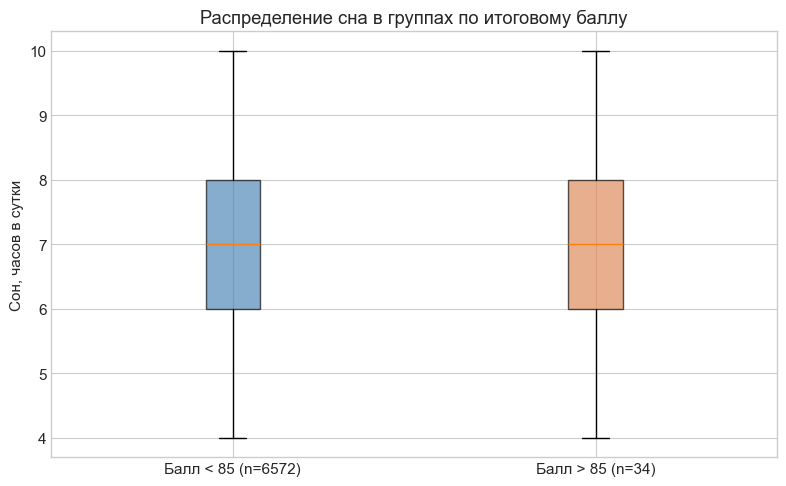

Строки с баллом ровно 85 исключены по условию: 1.
Медианы сна близки; группа с баллом >85 мала, поэтому сравнение ограничено.


In [27]:
sleep_below_85 = df.loc[df["Exam_Score"] < 85, "Sleep_Hours"]
sleep_above_85 = df.loc[df["Exam_Score"] > 85, "Sleep_Hours"]
excluded_85 = df["Exam_Score"].eq(85).sum()

fig, ax = plt.subplots(figsize=(8, 5))
boxes = ax.boxplot([sleep_below_85, sleep_above_85], patch_artist=True)
for box, color in zip(boxes["boxes"], ["#4682b4", "#dd8452"]):
    box.set_facecolor(color)
    box.set_alpha(0.65)
ax.set_xticks([1, 2], [f"Балл < 85 (n={len(sleep_below_85)})",
                       f"Балл > 85 (n={len(sleep_above_85)})"])
ax.set(title="Распределение сна в группах по итоговому баллу",
       ylabel="Сон, часов в сутки")
fig.tight_layout()
plt.show()

print(f"Строки с баллом ровно 85 исключены по условию: {excluded_85}.")
print("Медианы сна близки; группа с баллом >85 мала, поэтому сравнение ограничено.")

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

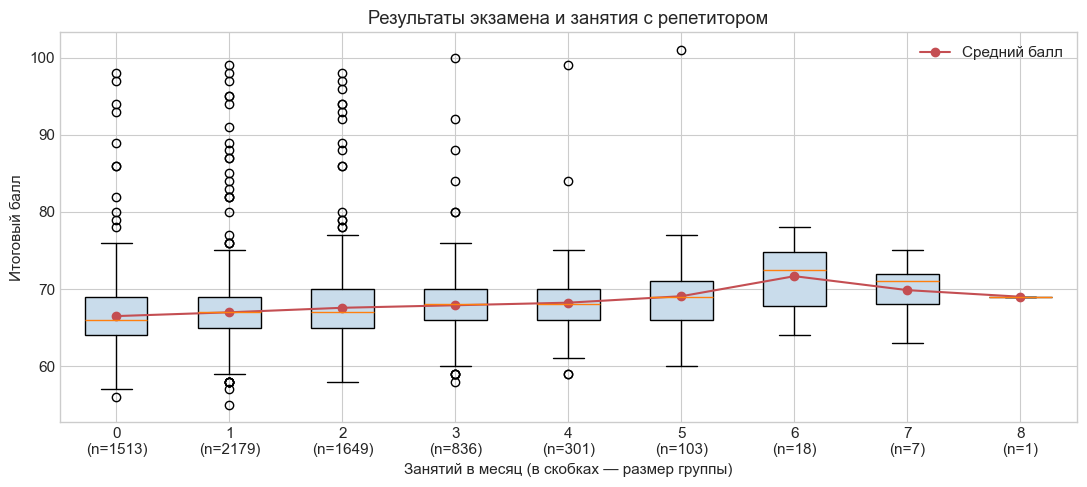

,count,mean
Tutoring_Sessions,,
0,1513,66.489755
1,2179,66.980266
2,1649,67.567010
3,836,67.894737
4,301,68.229236
5,103,69.067961
6,18,71.666667
7,7,69.857143
8,1,69.000000


Корреляция: 0.157. Есть слабая положительная связь.
Прямое причинное влияние не доказано; рост средних не строго монотонен.
В группах с 6–8 занятиями очень мало наблюдений.


In [28]:
tutor_summary = df.groupby("Tutoring_Sessions")["Exam_Score"].agg(["count", "mean", "std"])
tutor_correlation = df["Tutoring_Sessions"].corr(df["Exam_Score"])
tutor_groups = [group["Exam_Score"].to_numpy()
                for _, group in df.groupby("Tutoring_Sessions", sort=True)]

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot(tutor_groups, positions=tutor_summary.index, widths=0.55,
            patch_artist=True, boxprops={"facecolor": "#c9dceb"})
ax.plot(tutor_summary.index, tutor_summary["mean"], "o-", color="#c44e52",
        label="Средний балл")
ax.set_xticks(tutor_summary.index,
              [f"{sessions}\n(n={count})" for sessions, count
               in zip(tutor_summary.index, tutor_summary["count"])])
ax.set(title="Результаты экзамена и занятия с репетитором",
       xlabel="Занятий в месяц (в скобках — размер группы)", ylabel="Итоговый балл")
ax.legend()
fig.tight_layout()
plt.show()

display(tutor_summary[["count", "mean"]])
print(f"Корреляция: {tutor_correlation:.3f}. Есть слабая положительная связь.")
print("Прямое причинное влияние не доказано; рост средних не строго монотонен.")
print("В группах с 6–8 занятиями очень мало наблюдений.")

6. Как физическая активность влияет на успеваемость?

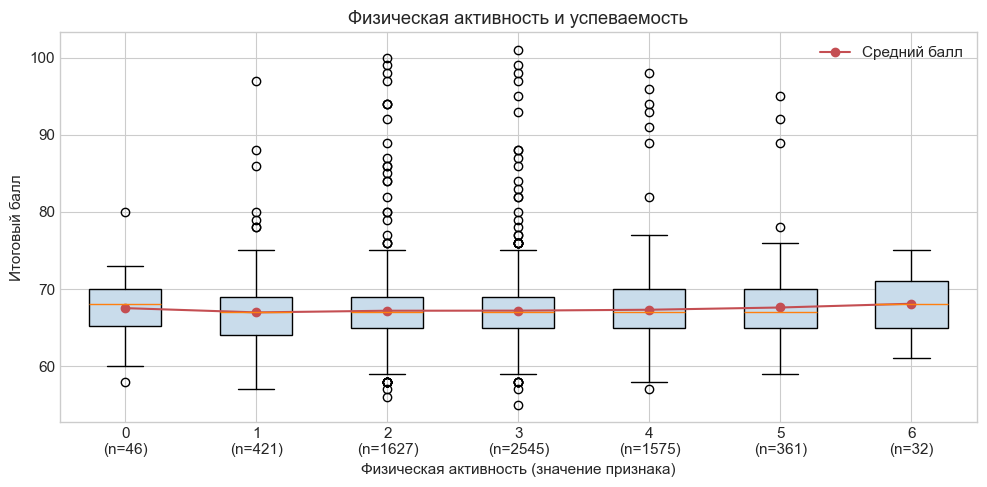

Корреляция: 0.028.
Распределения сильно перекрываются; выраженной линейной связи не видно.
Крайние группы малочисленны, а причинное влияние по графику установить нельзя.


In [29]:
activity_summary = df.groupby("Physical_Activity")["Exam_Score"].agg(["count", "mean"])
activity_groups = [group["Exam_Score"].to_numpy()
                   for _, group in df.groupby("Physical_Activity", sort=True)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(activity_groups, positions=activity_summary.index, widths=0.55,
            patch_artist=True, boxprops={"facecolor": "#c9dceb"})
ax.plot(activity_summary.index, activity_summary["mean"], "o-", color="#c44e52",
        label="Средний балл")
ax.set_xticks(activity_summary.index,
              [f"{activity}\n(n={count})" for activity, count
               in zip(activity_summary.index, activity_summary["count"])])
ax.set(title="Физическая активность и успеваемость",
       xlabel="Физическая активность (значение признака)", ylabel="Итоговый балл")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Корреляция: {df['Physical_Activity'].corr(df['Exam_Score']):.3f}.")
print("Распределения сильно перекрываются; выраженной линейной связи не видно.")
print("Крайние группы малочисленны, а причинное влияние по графику установить нельзя.")

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

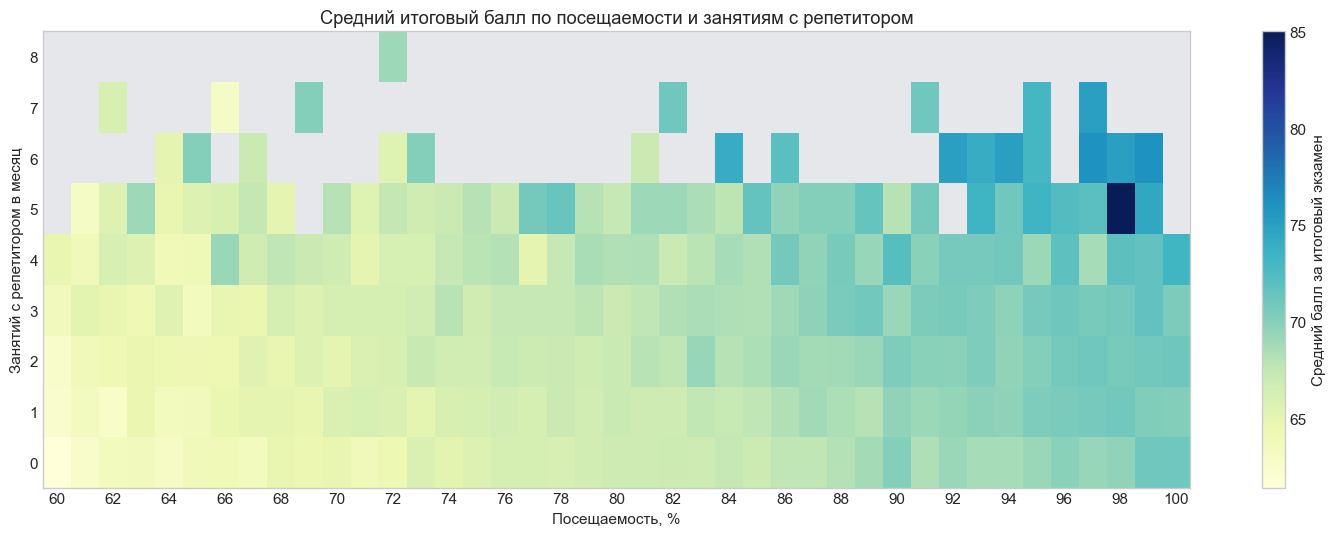

Каждая ячейка показывает средний балл для конкретного сочетания двух признаков.
Серые ячейки — сочетания без наблюдений; размеры групп различаются.


In [30]:
# При совпадении посещаемости и числа занятий усредняем итоговые баллы.
score_heatmap = df.pivot_table(index="Tutoring_Sessions", columns="Attendance",
                               values="Exam_Score", aggfunc="mean")
score_heatmap = score_heatmap.reindex(
    index=range(df["Tutoring_Sessions"].min(), df["Tutoring_Sessions"].max() + 1),
    columns=range(df["Attendance"].min(), df["Attendance"].max() + 1),
)
heatmap_colors = plt.get_cmap("YlGnBu").copy()
heatmap_colors.set_bad("#e5e7eb")  # Нет наблюдений: оставляем пропуски, не нули.

fig, ax = plt.subplots(figsize=(15, 5.5))
heatmap_image = ax.imshow(np.ma.masked_invalid(score_heatmap.to_numpy()),
                          aspect="auto", origin="lower", cmap=heatmap_colors)
x_positions = np.arange(0, len(score_heatmap.columns), 2)
ax.set_xticks(x_positions, score_heatmap.columns[x_positions])
ax.set_yticks(np.arange(len(score_heatmap.index)), score_heatmap.index)
ax.set(title="Средний итоговый балл по посещаемости и занятиям с репетитором",
       xlabel="Посещаемость, %", ylabel="Занятий с репетитором в месяц")
ax.grid(False)
fig.colorbar(heatmap_image, ax=ax, label="Средний балл за итоговый экзамен")
fig.tight_layout()
plt.show()

print("Каждая ячейка показывает средний балл для конкретного сочетания двух признаков.")
print("Серые ячейки — сочетания без наблюдений; размеры групп различаются.")